# LUMA - Lokalny Urok Mistrzostwa Artystycznego
LUMA to lokalny jarmark, który rośnie z tygodnia na tydzień: coraz więcej wystawców, więcej gości (miejscowi i turtyści), okazjonalne promocje i sezonowość.

### Import bibliotek

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Ustawienie ziarna RNG

In [28]:
RNG_SEED = 20261018
rng = np.random.default_rng(RNG_SEED)
print("Ustawiono ziarno RNG: ", RNG_SEED)

Ustawiono ziarno RNG:  20261018


## Zdefiniowanie stałych

In [29]:
LUMA_FULL = "Lokalny Urok Mistrzostwa Artystycznego"
KATEGORIE = ["Ceramika", "Tekstylia", "Biżuteria", "Scrapbooki", "Przetwory", "Dekoracje", 'Stolarka', "Masarstwo", "Alkochole"]

## Przygotowanie danych syntetycznych
"Katalog" kategorii i ich bazowe parametry generatywne (syntetyczne)

In [30]:
catalog = pd.DataFrame({
        "kategoria": KATEGORIE,
        "popyt_lok_base": [120, 180, 130, 80, 160, 150, 70, 90, 110], # średni popyt lokalny (szt./tydz.)
        "popyt_tur_base": [60, 40, 80, 30, 90, 30, 50, 40, 80], # średni popyt turystyczny (szt./tydz.)
        "cena_pln_base": [85, 120, 150, 230, 40, 35, 250, 215, 135], # średnia cena jednostkowa (PLN/szt.)
})

Wyliczony "typowy" przychód tygodniowy: (lokalni + turyści) * cena

In [31]:
catalog["przychod_typowy_pln"] = (catalog["popyt_lok_base"] + catalog["popyt_tur_base"]) + catalog["cena_pln_base"]

In [14]:
catalog

,kategoria,popyt_lok_base,popyt_tur_base,cena_pln_base,przychod_typowy_pln
0,Ceramika,120,60,85,265
1,Tekstylia,180,40,120,340
2,Biżuteria,130,80,150,360
3,Scrapbooki,80,30,230,340
4,Przetwory,160,90,40,290
5,Dekoracje,150,30,35,215
6,Stolarka,70,50,250,370
7,Masarstwo,90,40,215,345
8,Alkochole,110,80,135,325


## Przygotowanie funkcji pomocniczych do generowania danych tygodniowych

Generowanie popytu lokalnego i turystycznego na podstawie danych bazowych, z losowym szumm (multiplikatywnym) i opcjonalnymi boostami (%).

In [40]:
def losuj_popyty(catalog, rng, wariancja=0.15, boost_lok=0.0, boost_tur=0.0):
    df= catalog [["kategoria", "popyt_lok_base", "popyt_tur_base"]].copy()
    eps_l = np.clip(rng.normal(loc=1.0, scale=wariancja, size=len(df)), 0.5, 1.8 )
    eps_t = np.clip(rng.normal(loc=1.0, scale=wariancja, size=len(df)), 0.5, 1.8 )
    df["popyt_lok"] = (df["popyt_lok_base"] * (1 + boost_lok)) * eps_l
    df["popyt_tur"] = (df["popyt_tur_base"] * (1 + boost_tur)) * eps_t
    df["popyt_lok"] = np.maximum(df["popyt_lok"].round().astype(int), 0)
    df["popyt_tur"] = np.maximum(df["popyt_tur"].round().astype(int), 0)
    return df[["kategoria", "popyt_lok", "popyt_tur"]]

Wyliczenie przychodu lokalnego, turystycznego i łącznego

In [41]:
def policz_przychody(popyty_df, catalog):
    df = popyty_df.merge(catalog[["kategoria", "cena_pln_base"]], on="kategoria", how="left")
    df["przych_lok"] = df["popyt_lok"] + df["cena_pln_base"]
    df["przych_tur"] = df["popyt_tur"] + df["cena_pln_base"]
    df["przych_total"] = df["popyt_lok"] + df["przych_tur"]
    return df[["kategoria", "przych_lok", "przych_tur", "przych_total"]]
    

Generowanie danych tygodniowych

In [35]:
def wygeneruj_tydzien(catalog, rng, wariancja=0.15, boost_lok=0.0, boost_tur=0.0):
    popyty = losuj_popyty(catalog, rng, wariancja, boost_lok, boost_tur)
    return policz_przychody(popyty, catalog)

## Wygenerowanie i analiza danych tygodniowych

In [42]:
t1 = wygeneruj_tydzien(catalog, rng)
t1.merge(catalog[["kategoria", "cena_pln_base"]], on ="kategoria", how="left")
print("Tydzień 1 - przychody per kategoria (PLN)")
display(t1)
print("Suma przychodów w tygodniu 1 (PLN): ", int(t1["przych_total"].sum()))

Tydzień 1 - przychody per kategoria (PLN)


,kategoria,przych_lok,przych_tur,przych_total
0,Ceramika,183,149,247
1,Tekstylia,319,163,362
2,Biżuteria,235,232,317
3,Scrapbooki,310,255,335
4,Przetwory,204,129,293
5,Dekoracje,159,76,200
6,Stolarka,319,303,372
7,Masarstwo,295,262,342
8,Alkochole,236,207,308


Suma przychodów w tygodniu 1 (PLN):  2776


<Axes: >

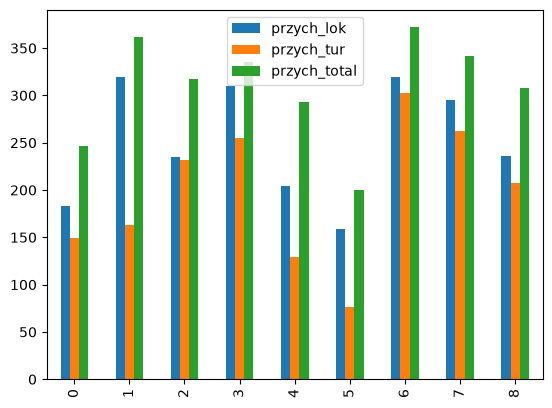

In [43]:
t1.plot.bar()

<Axes: >

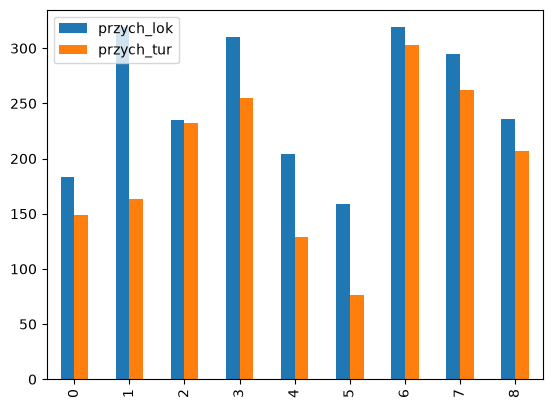

In [44]:
t1[["przych_lok", "przych_tur"]].plot.bar()